# 12 Stationsbilder neben dem Ternärdiagramm

Teil 4: Stationsbilder und Befunde

**Worum es geht**
- Das Ternärdiagramm aus Notebook 11 bringt ein Produkt (P = c · V · ΔT) auf eine Summe und verliert dabei das Niveau, also wie viel Wasser und wie warm.
- Drei Darstellungen ohne diese Einschränkung: Kennlinie (Volumenstrom über Leistung, beide Achsen logarithmisch), Carpet-Plot (Rücklauf und Durchfluss als Farbe über Tag und Stunde), Dauerlinie (Werte nach Größe sortiert).
- Frage: Welche Darstellung findet Stationen, die die anderen übersehen? Welche Kennzahl misst die Wirkung einer Begehung?

**Daten**
- liest: `data/processed/real_meters/` (Stundenreihen), Begehungstermine über `src/load_begehungen.py`
- schreibt: `outputs/stationsbilder/` (Unterordner `kennlinie/stunde`, `kennlinie/tag`, `carpet`, `dauerlinie`)
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/stationsbilder.py` und `src/ternaer.py`, Tests in `tests/test_stationsbilder.py`.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import load_begehungen as lb
from src import stationsbilder as sb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

METER_DIR = ROOT / "data" / "processed" / "real_meters"
OUT_DIR = ROOT / "outputs" / "stationsbilder"

#Gegenbeispiele wie in Notebook 11: 68956351 mit jahrelang offenem Ventil, 69631918 unauffällig
BEISPIEL_AUFFAELLIG = 68956351
BEISPIEL_UNAUFFAELLIG = 69631918

t0 = time.time()
serien = tn.lade_serien(METER_DIR)
roh = lb.begehung_dates_by_meter()
begehungsdatum = {int(k): (v[0] if isinstance(v, (list, tuple)) else v)
                  for k, v in roh.items()}
print(f"{len(serien)} Zaehlerreihen in {time.time() - t0:.0f} s")
print(f"Begehungsdatum fuer {len(begehungsdatum)} Zaehler")

93 Zaehlerreihen in 1 s
Begehungsdatum fuer 56 Zaehler


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 1 Die Brücke zum Ternärdiagramm

- Der Durchflussanteil aus Notebook 11, cov(log P, log V) / var(log P), ist zugleich die Steigung der Kennlinie.
- Beide Module müssen deshalb je Station dieselbe Zahl liefern. Die nächste Zelle prüft das.

In [2]:
proben = []
for meter in sorted(serien)[:25]:
    tab = sb.punkttabelle(serien[meter], meter,
                          begehungsdatum=begehungsdatum.get(meter))
    if len(tab) < sb.MIN_PUNKTE:
        continue
    proben.append({
        "meter": meter,
        "steigung": sb.kennlinienfit(tab)["steigung"],
        "anteil_mod_flow": tn.modulationszerlegung(tab)["anteil_mod_flow"],
    })

probe = pd.DataFrame(proben)
probe["differenz"] = (probe["steigung"] - probe["anteil_mod_flow"]).abs()
print(f"{len(probe)} Stationen geprueft")
print(f"groesste Abweichung: {probe['differenz'].max():.2e}")
print(probe.head(6).round(6).to_string(index=False))

24 Stationen geprueft
groesste Abweichung: 0.00e+00
   meter  steigung  anteil_mod_flow  differenz
53198226  0.853951         0.853951        0.0
58177363  0.853542         0.853542        0.0
58177384  1.209108         1.209108        0.0
61620222  0.941248         0.941248        0.0
65273846  1.034867         1.034867        0.0
66761022  0.612843         0.612843        0.0


- Die Abweichung liegt im Rahmen der Rechengenauigkeit (0 bei 24 Stationen).
- Die Kennlinie liefert zusätzlich das Niveau, die Spreizung als Hilfslinien und das Bestimmtheitsmaß r² (wie gut die Punkte auf einer Geraden liegen, 1 = perfekt).

## 2 Zwei Stationen im Bild

- Linien gleicher Spreizung sind Geraden mit Steigung 1, weil V = P · 1000 / (c · ΔT) gilt.
- Die Farbe zeigt den Rücklauf. Die Performance wäre auf Stundenebene nur die Spreizung in anderer Einheit.

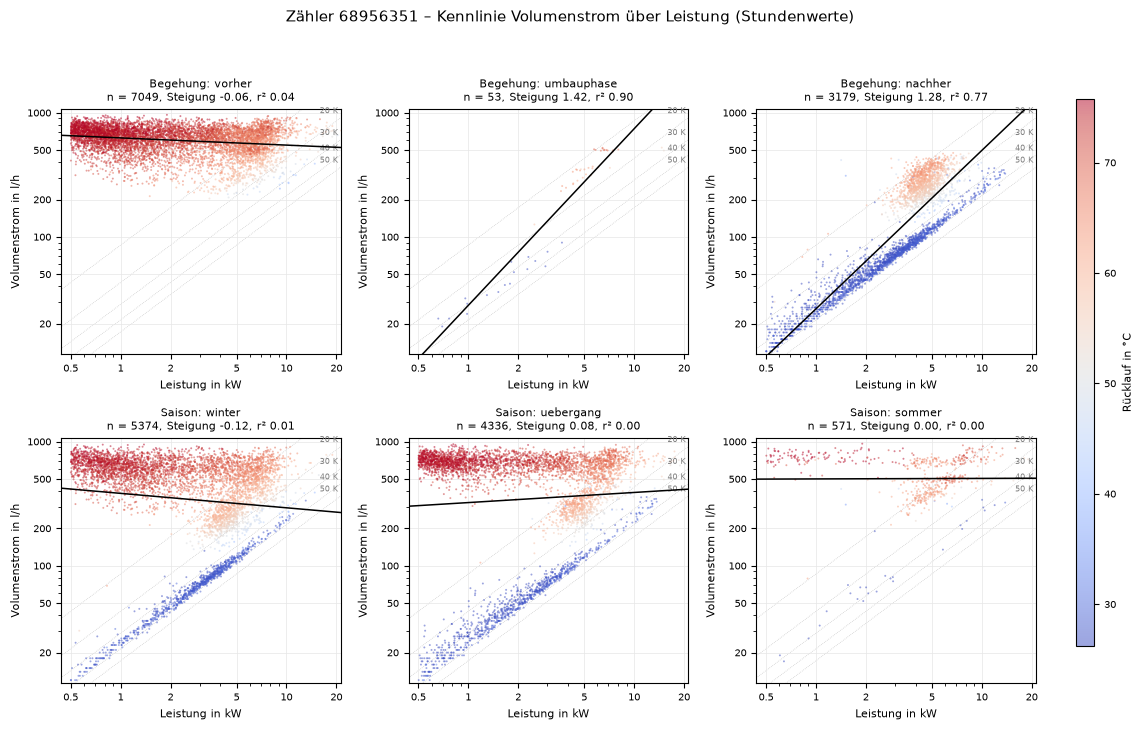

In [3]:
tabellen = {}
for meter in (BEISPIEL_AUFFAELLIG, BEISPIEL_UNAUFFAELLIG):
    for aufl in ("stunde", "tag"):
        tabellen[(meter, aufl)] = sb.punkttabelle(
            serien[meter], meter, aufloesung=aufl,
            begehungsdatum=begehungsdatum.get(meter))

fig = sb.kennliniengrafik(tabellen[(BEISPIEL_AUFFAELLIG, "stunde")],
                          BEISPIEL_AUFFAELLIG, "Stundenwerte")
plt.show()

- 68956351 vorher: Wolke waagerecht bei rund 600 l/h, Rücklauf 65 bis 75 °C, Steigung −0,06 bei r² 0,04. Es gibt also keine Kennlinie.
- Nachher: Gerade mit Steigung 1,28 und r² 0,77. Das passt zur Reparatur eines offenen Ventils.
- Die Saisonpanels mischen beide Phasen und beschreiben keine davon.

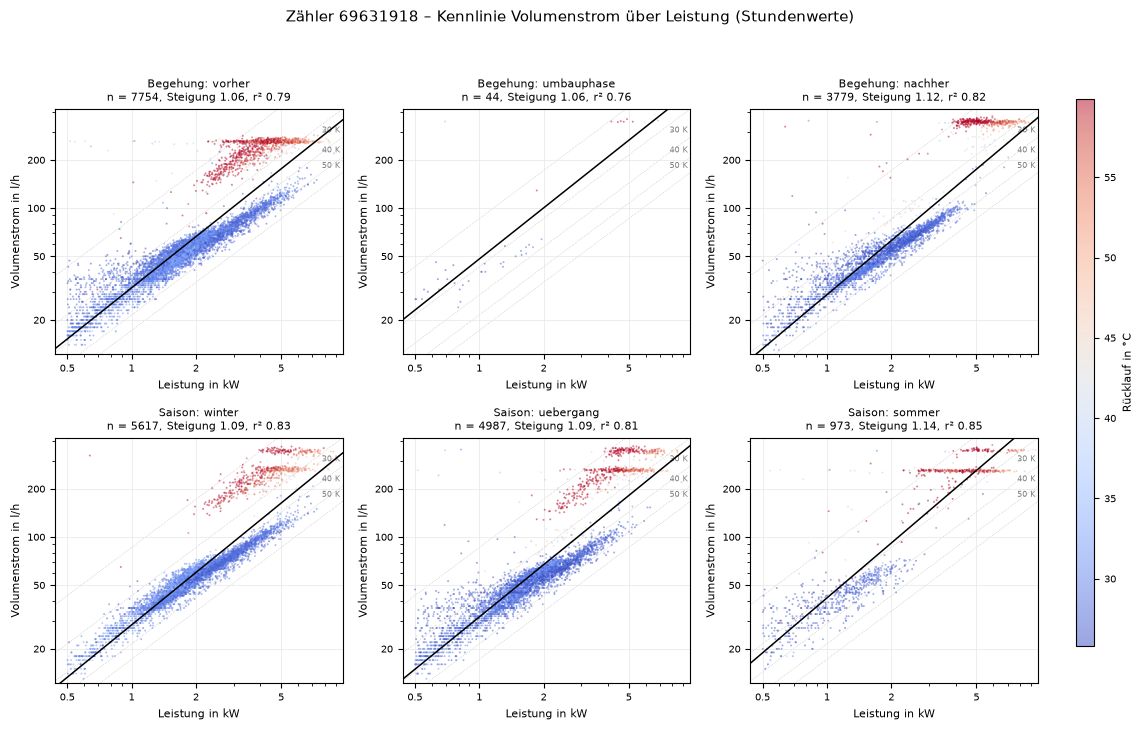

In [4]:
fig = sb.kennliniengrafik(tabellen[(BEISPIEL_UNAUFFAELLIG, "stunde")],
                          BEISPIEL_UNAUFFAELLIG, "Stundenwerte")
plt.show()

- Unauffällige Station 69631918: Steigung in allen Panels 1,06 bis 1,14, also gleiches Regelverhalten über Jahreszeiten und Begehung.
- Ein roter Nebenast bei 250 bis 300 l/h zeigt zeitweise dasselbe Muster wie 68956351 vor der Reparatur. Im Dreieck war das nur eine zweite Wolke ohne Deutung.

## 3 Export für alle Stationen

- Alle drei Darstellungen für alle Stationen als Bilder, dazu Kennzahlentabellen für die Auswertung.

In [5]:
t0 = time.time()
kennzahlen = sb.exportiere(serien, OUT_DIR, begehungsdatum=begehungsdatum,
                           fortschritt=True)
print(f"\nExport in {time.time() - t0:.0f} s")

for name, tab in kennzahlen.items():
    print(f"{name}: {len(tab)} Zeilen, {tab['meter'].nunique()} Stationen")

for unter in ("kennlinie/stunde", "kennlinie/tag", "carpet", "dauerlinie"):
    pfad = OUT_DIR / unter
    n = len(list(pfad.glob("*.png"))) if pfad.exists() else 0
    print(f"PNG {unter}: {n}")

10/93 Stationen


20/93 Stationen


30/93 Stationen


40/93 Stationen


50/93 Stationen


60/93 Stationen


70/93 Stationen


80/93 Stationen


90/93 Stationen



Export in 212 s
kennlinie: 1116 Zeilen, 93 Stationen
carpet: 93 Zeilen, 93 Stationen
dauerlinie: 1116 Zeilen, 93 Stationen
PNG kennlinie/stunde: 95
PNG kennlinie/tag: 99
PNG carpet: 101
PNG dauerlinie: 99


- Kennlinie und Dauerlinie haben je 1.116 Zeilen, der Carpet-Plot 93, jeweils für 93 Stationen.
- Stationen ohne verwertbare Punkte stehen mit n = 0 in den Tabellen und bekommen kein Bild. Die Bildzahlen in der Ausgabe zählen alle Dateien im Ordner, auch ältere aus früheren Läufen.

## 4 Was die Kennlinie über die Stationen sagt

- Winterpanel auf Stundenebene, wie in Notebook 11.
- Drei Klassen nach Steigung: über 0,7 durchflussgeführt, 0,3 bis 0,7 gemischt, unter 0,3 steht der Durchfluss fest.

In [6]:
kennlinie = kennzahlen["kennlinie"]
win = kennlinie[(kennlinie["schnitt"] == "saison")
                & (kennlinie["gruppe"] == "winter")
                & (kennlinie["aufloesung"] == "stunde")].copy()
win = win[win["steigung"].notna()]
print(f"{len(win)} Stationen mit belastbarem Winterfit")
print(win[["steigung", "r2", "residuum_sd", "flow_median_lh",
           "performance_median"]].describe().round(3).to_string())

klassen = [("flussgefuehrt (Steigung ueber 0,7)", 0.7, np.inf),
           ("gemischt (0,3 bis 0,7)", 0.3, 0.7),
           ("Durchfluss steht fest (unter 0,3)", -np.inf, 0.3)]
zeilen = []
for name, unten, oben in klassen:
    teil = win[(win["steigung"] > unten) & (win["steigung"] <= oben)]
    zeilen.append({"klasse": name, "n": len(teil),
                   "r2_median": teil["r2"].median(),
                   "flow_median_lh": teil["flow_median_lh"].median(),
                   "performance_median": teil["performance_median"].median()})
print()
print(pd.DataFrame(zeilen).round(3).to_string(index=False))

92 Stationen mit belastbarem Winterfit
       steigung      r2  residuum_sd  flow_median_lh  performance_median
count    92.000  92.000       92.000          92.000              92.000
mean      0.800   0.627        0.319         494.962              29.870
std       0.338   0.280        0.168        1653.013              10.576
min      -0.116   0.005        0.034          34.000               5.699
25%       0.644   0.454        0.210          94.000              23.173
50%       0.898   0.721        0.264         153.000              30.878
75%       1.026   0.854        0.406         237.500              36.809
max       1.358   0.937        0.890       11510.000              47.916

                            klasse  n  r2_median  flow_median_lh  performance_median
flussgefuehrt (Steigung ueber 0,7) 64      0.807           133.0              34.483
            gemischt (0,3 bis 0,7) 18      0.485           150.0              23.376
 Durchfluss steht fest (unter 0,3) 10      0.021

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(win["steigung"], bins=24, color="steelblue", alpha=0.8)
axes[0].axvline(0.3, color="black", lw=0.8, ls="--")
axes[0].axvline(0.7, color="black", lw=0.8, ls="--")
axes[0].set_xlabel("Steigung der Kennlinie")
axes[0].set_ylabel("Stationen")
axes[0].set_title("Winterpanel, Stundenwerte")

punkte = axes[1].scatter(win["steigung"], win["performance_median"],
                         c=win["r2"], cmap="viridis", s=22)
axes[1].set_xlabel("Steigung der Kennlinie")
axes[1].set_ylabel("Performance in kWh/m³ (Median)")
axes[1].set_title("Steigung gegen Performance")
axes[1].grid(alpha=0.25)
fig.colorbar(punkte, ax=axes[1], label="r²")
fig.tight_layout()
plt.show()

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37553/1694900368.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [8]:
print("Spearman gegen die Performance, Winterpanel Stunde")
for spalte in ("steigung", "r2", "residuum_sd", "flow_median_lh",
               "dt_median_k"):
    teil = win[[spalte, "performance_median"]].dropna()
    rho, p = stats.spearmanr(teil[spalte], teil["performance_median"])
    print(f"{spalte:>16}: rho {rho:+.3f}  p {p:.2e}  n {len(teil)}")

teil = win[["steigung", "r2"]].dropna()
rho, p = stats.spearmanr(teil["steigung"], teil["r2"])
print(f"\nSteigung gegen r2: rho {rho:+.3f}, p {p:.2e}")

Spearman gegen die Performance, Winterpanel Stunde
        steigung: rho +0.481  p 1.22e-06  n 92
              r2: rho +0.557  p 8.16e-09  n 92
     residuum_sd: rho -0.291  p 4.88e-03  n 92
  flow_median_lh: rho -0.673  p 2.09e-13  n 92
     dt_median_k: rho +1.000  p 0.00e+00  n 92

Steigung gegen r2: rho +0.617, p 5.72e-11


- Steigung gegen Performance +0,481, das Spiegelbild der −0,48 aus Notebook 11. Regelung über den Durchfluss geht mit besserer Performance einher.
- Steigung nahe 0 heißt: Der Durchfluss steht fest. Das ist keine Regelung über die Spreizung. Diese 10 Stationen liegen auf keiner Kennlinie (r² 0,02) und kommen auf 10,9 gegen 34,5 kWh/m³ bei den durchflussgeführten.
- `dt_median_k` gegen Performance (+1,000) und Durchflussmedian (−0,673) sind Definitionen, keine Befunde. Auf Stundenebene gilt Performance = 1,163 · ΔT.
- Mehr eigene Information als das Bestimmtheitsmaß trägt die Streuung der Punkte um die Kennlinie (Residuenstreuung).

## 5 Der Carpet-Plot

- Ein Bild je Station: jede Spalte ein Tag, jede Zeile eine Stunde, die Farbe ist der Messwert.
- Zeigt Stillstand als weiße Fläche sowie Zeitprogramme und Nachtabsenkung. Das fehlt in den Punktwolken.

In [9]:
fig = sb.carpetgrafik(serien[BEISPIEL_AUFFAELLIG], BEISPIEL_AUFFAELLIG,
                      begehungsdatum=begehungsdatum.get(BEISPIEL_AUFFAELLIG))
plt.show()

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37553/2840161308.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


- 68956351: senkrechte Kante am Begehungstermin. Davor rund um die Uhr warmer Rücklauf und hoher Durchfluss, danach ein klares Zeitmuster.
- Weiße Fläche ganz links: Vor November 2022 gibt es nur einen Wert je Tag. Diesen Datenbefund zeigt keine Punktwolke.

In [10]:
carpet = kennzahlen["carpet"]
print(carpet[["nachtabsenkung_k", "sommer_nacht_anteil", "stillstand_anteil",
              "rt_ueber_schwelle_anteil"]].describe().round(3).to_string())

zus = carpet.merge(win[["meter", "performance_median", "steigung", "r2"]],
                   on="meter", how="inner")
print(f"\nmit Winterfit verknuepft: {len(zus)} Stationen")
for spalte in ("nachtabsenkung_k", "sommer_nacht_anteil",
               "stillstand_anteil", "rt_ueber_schwelle_anteil"):
    t = zus[[spalte, "performance_median"]].dropna()
    rho, p = stats.spearmanr(t[spalte], t["performance_median"])
    print(f"{spalte:>26}: rho {rho:+.3f}  p {p:.2e}  n {len(t)}")

print("\nZehn Stationen mit dem laengsten warmen Ruecklauf")
print(carpet.nlargest(10, "rt_ueber_schwelle_anteil")[
    ["meter", "rt_ueber_schwelle_anteil", "nachtabsenkung_k",
     "sommer_nacht_anteil", "stillstand_anteil"]].round(3).to_string(
         index=False))

       nachtabsenkung_k  sommer_nacht_anteil  stillstand_anteil  rt_ueber_schwelle_anteil
count            93.000               93.000             93.000                    93.000
mean              4.271                0.420              0.317                     0.411
std               7.303                0.313              0.209                     0.312
min              -8.800                0.008              0.000                     0.000
25%              -0.300                0.176              0.148                     0.147
50%               2.700                0.302              0.295                     0.328
75%               7.700                0.707              0.454                     0.656
max              28.900                1.000              0.896                     0.999

mit Winterfit verknuepft: 92 Stationen
          nachtabsenkung_k: rho +0.146  p 1.66e-01  n 92
       sommer_nacht_anteil: rho -0.403  p 6.88e-05  n 92
         stillstand_anteil: rho +0.3

- Nachtabsenkung im Median 2,7 K. Ein Viertel der Stationen fährt nachts praktisch durch. Mit der Performance nur schwach verbunden (rho = +0,15).
- Durchströmte Sommernächte gehen mit schlechterer Performance einher (−0,40, p = 0,0001). Das passt zum Befund „Hoher Rücklauf im Sommer“ aus Notebook 17.
- Unter den zehn Stationen mit dem längsten warmen Rücklauf stehen die beiden Ausreißer aus Notebook 07 (66761022, 58202380).

## 6 Die Dauerlinie und die Wirkung der Begehung

- Die Dauerlinie sortiert alle Werte nach Größe. Man liest ab, an wie viel Prozent der Zeit ein Wert überschritten wird.

In [11]:
fig = sb.dauerliniengrafik(tabellen[(BEISPIEL_AUFFAELLIG, "stunde")],
                           tabellen[(BEISPIEL_AUFFAELLIG, "tag")],
                           BEISPIEL_AUFFAELLIG)
plt.show()

/var/folders/wd/3bp2dy592j9czn536fmq110w0000gn/T/ipykernel_37553/3133401110.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


- 68956351: Rücklauf vor der Begehung fast immer über 50 °C, nachher an gut 40 % der Zeit.
- Die nächste Zelle vergleicht über alle Stationen gepaart vorher gegen nachher (Wilcoxon-Test).

In [12]:
dauer = kennzahlen["dauerlinie"]
for groesse, feld, richtung in (("rt_c", "ueber_schwelle_anteil", "kleiner"),
                                ("performance", "p50", "groesser")):
    teil = dauer[(dauer["schnitt"] == "begehung")
                 & (dauer["groesse"] == groesse)]
    breit = teil.pivot_table(index="meter", columns="gruppe", values=feld)
    breit = breit.dropna(subset=["vorher", "nachher"])
    diff = breit["nachher"] - breit["vorher"]
    besser = int((diff < 0).sum()) if richtung == "kleiner" \
        else int((diff > 0).sum())
    w, p = stats.wilcoxon(breit["nachher"], breit["vorher"])
    print(f"{groesse}/{feld}: n = {len(breit)}, Median der Differenz "
          f"{diff.median():+.4f}, besser bei {besser}, Wilcoxon p {p:.4f}")

beg = kennlinie[(kennlinie["schnitt"] == "begehung")
                & (kennlinie["aufloesung"] == "stunde")]
for feld in ("steigung", "r2"):
    breit = beg.pivot_table(index="meter", columns="gruppe", values=feld)
    breit = breit.dropna(subset=["vorher", "nachher"])
    diff = breit["nachher"] - breit["vorher"]
    w, p = stats.wilcoxon(breit["nachher"], breit["vorher"])
    print(f"{feld}: n = {len(breit)}, Median der Differenz "
          f"{diff.median():+.3f}, Wilcoxon p {p:.4f}, "
          f"deutlich hoch {int((diff > 0.2).sum())}, "
          f"deutlich runter {int((diff < -0.2).sum())}")

rt_c/ueber_schwelle_anteil: n = 47, Median der Differenz -0.0140, besser bei 28, Wilcoxon p 0.0957
performance/p50: n = 45, Median der Differenz +0.7337, besser bei 27, Wilcoxon p 0.0689
steigung: n = 44, Median der Differenz -0.011, Wilcoxon p 0.6731, deutlich hoch 6, deutlich runter 6
r2: n = 44, Median der Differenz -0.011, Wilcoxon p 0.7594, deutlich hoch 4, deutlich runter 6


In [13]:
breit = beg.pivot_table(index="meter", columns="gruppe", values="steigung")
breit = breit.dropna(subset=["vorher", "nachher"])
breit["differenz"] = breit["nachher"] - breit["vorher"]
print("Groesste Veraenderung der Kennliniensteigung um die Begehung")
print(breit.reindex(breit["differenz"].abs().sort_values(
    ascending=False).index).head(8)[
        ["vorher", "nachher", "differenz"]].round(3).to_string())

Groesste Veraenderung der Kennliniensteigung um die Begehung
gruppe    vorher  nachher  differenz
meter                               
68956351  -0.058    1.276      1.334
72167783   0.876    0.042     -0.833
80912190   0.181    0.983      0.801
80912173   0.629    0.026     -0.603
80912197   1.240    0.745     -0.496
68956359   1.035    0.563     -0.473
68956356   0.877    0.450     -0.427
80912196   0.543    0.862      0.319


- Die Dauerlinien zeigen eine schwache Veränderung: Stunden mit Rücklauf über 50 °C −1,4 Prozentpunkte (n = 47, p = 0,096), Tagesperformance +0,73 kWh/m³ (n = 45, p = 0,069). Beides ist nicht gesichert.
- Steigung (p = 0,67) und Bestimmtheitsmaß (p = 0,76) ändern sich nicht. Das gleicht der Modulationsart in Notebook 11.
- Ausnahme ist 68956351 mit einem Sprung der Steigung von −0,058 auf 1,276.
- Ohne Kontrollgruppe ist das nur konsistent mit einer Wirkung der Begehung.

## 7 Finden die Darstellungen dieselben Stationen?

- Je Kennzahl die zehn auffälligsten Stationen. Gezählt wird, wie viele Stationen zwei Listen gemeinsam haben.

In [14]:
tab = win.merge(carpet, on="meter", how="inner")
regeln = {
    "Steigung klein": ("steigung", True),
    "r2 klein": ("r2", True),
    "Residuenstreuung gross": ("residuum_sd", False),
    "Durchflussmedian gross": ("flow_median_lh", False),
    "Ruecklauf lange ueber 50 Grad": ("rt_ueber_schwelle_anteil", False),
    "Sommernachts durchstroemt": ("sommer_nacht_anteil", False),
}

tops = {}
for name, (spalte, klein) in regeln.items():
    tops[name] = set(tab.nsmallest(10, spalte)["meter"] if klein
                     else tab.nlargest(10, spalte)["meter"])

namen = list(tops)
ueber = pd.DataFrame([[len(tops[a] & tops[b]) for b in namen] for a in namen],
                     index=namen, columns=namen)
print("Gemeinsame Stationen in den Top-10-Listen")
print(ueber.to_string())

haeufig = pd.Series([m for s in tops.values() for m in s]).value_counts()
print(f"\nStationen in mindestens einer Liste: {haeufig.size} von {len(tab)}")
print("in mehreren Listen:")
print(haeufig[haeufig > 1].to_string())

Gemeinsame Stationen in den Top-10-Listen
                               Steigung klein  r2 klein  Residuenstreuung gross  Durchflussmedian gross  Ruecklauf lange ueber 50 Grad  Sommernachts durchstroemt
Steigung klein                             10         9                       2                       7                              6                          3
r2 klein                                    9        10                       3                       6                              5                          2
Residuenstreuung gross                      2         3                      10                       3                              0                          2
Durchflussmedian gross                      7         6                       3                      10                              6                          4
Ruecklauf lange ueber 50 Grad               6         5                       0                       6                             10              

In [15]:
print(f"Rang von {BEISPIEL_AUFFAELLIG}, der Station mit dem bekannten "
      f"Ventildefekt")
zeilen = []
for name, (spalte, klein) in regeln.items():
    rang = tab[spalte].rank(ascending=klein, method="min")
    zeilen.append({"kennzahl": name, "rang": int(
        rang[tab["meter"] == BEISPIEL_AUFFAELLIG].iloc[0]),
        "von": len(tab)})
print(pd.DataFrame(zeilen).to_string(index=False))

Rang von 68956351, der Station mit dem bekannten Ventildefekt
                     kennzahl  rang  von
               Steigung klein     1   92
                     r2 klein     3   92
       Residuenstreuung gross     1   92
       Durchflussmedian gross    10   92
Ruecklauf lange ueber 50 Grad    14   92
    Sommernachts durchstroemt    17   92


- Wenig Überschneidung: Nur 25 von 92 Stationen stehen überhaupt in einer der sechs Listen. Steigung und Bestimmtheitsmaß sind fast deckungsgleich.
- 68956351 findet die Kennlinie am besten (Platz 1 bei Steigung und Residuenstreuung).
- Die Ausreißer finden Durchflussmedian und warmer Rücklauf, die Kennlinie kaum. Genau diese Größen gehen im Dreieck verloren.

## Zusammenfassung & Bewertung

**Ergebnis**
- Steigung nahe 0 heißt feststehender Durchfluss. Diese Stationen haben die schlechteste Performance.
- Die Dauerlinien-Kennzahlen deuten nach den Begehungen eine Verbesserung an (nicht gesichert), Modulationsart und Kennlinie ändern sich gar nicht. Als Erfolgsmaß eignet sich der Überschreitungsanteil deshalb eher als die Kennlinie.

**Belastbar**
- Kennliniensteigung und Durchflussanteil des Dreiecks sind dieselbe Zahl. Die Kennlinie zeigt zusätzlich Niveau und Residuenstreuung.

**Schwach**
- Korrelationen mit der Performance sind auf Stundenebene zum Teil Folgen der Definition.
- Die Schwelle von 50 °C ist gesetzt. Der Überschreitungsanteil reagiert empfindlich darauf.
- Die Veränderungen bei Rücklauf und Performance sind nicht signifikant (p = 0,096 und 0,069), eine Kontrollgruppe fehlt.

**Offen**
- Rücklaufschwelle und Auffälligkeitsgrenze für die Steigung festlegen.
- Abgleich der 25 Stationen mit der Trefferliste aus Notebook 17.
- Wann welcher Zähler nur Tageswerte liefert, ist nicht dokumentiert. Das betrifft alle Auswertungen auf Stundenebene.
- Der Vergleich mit dem Vorjahr zum selben Kalenderzeitpunkt steht aus.